# Q2: Bonferroni correction for Arena's rank spreads

Arena gives every model a 95% confidence interval for its score and turns those intervals into a **rank spread** [best, worst]. In Q1 we found that each model's rank spread contains its true rank 99.9% of the time, but **all 129 rank spreads are right at the same time in only 90.9%** of simulated datasets, short of the 95% one would want for a whole leaderboard.

This notebook asks whether the simplest multiplicity correction, **Bonferroni**, fixes that, and what it costs.

**Short answer.** Bonferroni works: in all 1,000 simulated datasets every rank spread contained the true rank. But it overcorrects. Rank spreads become 71% wider, while a much smaller correction (multiplier 2.1 instead of 1.96) would already reach 95%.

The numbers come from `q2.py`, which runs Arena's method and Bonferroni on the same 1,000 simulated datasets as Q1. This notebook only reads the saved results in `results/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import norm

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
summary = pd.read_csv(ROOT / "results/q2_summary.csv", index_col=0)
per_model = pd.read_csv(ROOT / "results/q2_per_model.csv")
sweep = pd.read_csv(ROOT / "results/q2_sweep.csv")
real = pd.read_csv(ROOT / "results/q2_real.csv")

M = len(per_model)
Z_ARENA, Z_BONF = norm.ppf(0.975), norm.ppf(1 - 0.05 / (2 * M))
Z_ENOUGH = sweep.loc[sweep.rs_all_cover >= 0.95, "z"].min()   # smallest z on the grid where all rank spreads hold 95%

# One color per procedure, the same in every figure
ARENA, BONF = "#2a78d6", "#eb6834"
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
print(f"M = {M} models; Arena z = {Z_ARENA:.2f}, Bonferroni z = {Z_BONF:.2f}")

M = 129 models; Arena z = 1.96, Bonferroni z = 3.55


## 1. The correction

Each model's interval is $\hat\beta_m \pm z\,\mathrm{SE}_m$. Arena uses $z = 1.96$, so each interval misses its true score 5% of the time. With 129 intervals, about 6.5 of them miss in an average dataset.

Bonferroni gives each interval a miss rate of $5\%/M$ instead of $5\%$. Then

$$P(\text{at least one of the } M \text{ intervals misses}) \le M \times \frac{5\%}{M} = 5\%,$$

whatever the correlation between the estimates. For $M = 129$ this means $z = 3.55$ instead of $1.96$: every interval becomes 1.8 times wider.

**Why this also protects the ranks.** Arena puts model A above model B only when A's interval lies entirely above B's (the *overlap rule*). If every interval contains its true score, that can only happen when A really is better. So whenever all intervals are right, all rank spreads are right too, and Bonferroni makes "all intervals right" happen at least 95% of the time.

## 2. Result 1: Bonferroni reaches the target

Each row is averaged over the 1,000 simulated datasets. The ± values are Monte Carlo standard errors.

In [2]:
def cell(metric, proc, percent=True):
    v, se = summary.loc[metric, proc], summary.loc[metric, f"{proc}_mc_se"]
    return f"{100 * v:.1f}% ± {100 * se:.1f}" if percent else f"{v:.2f} ± {se:.2f}"

rows = [
    ("Each rank spread contains the true rank", "rank interval coverage, per model", True),
    ("All rank spreads contain the true ranks", "rank interval coverage, simultaneous (all models)", True),
    ("All score intervals contain the true scores", "score CIs: all cover (simultaneous)", True),
    ("Datasets with any wrong ordering", "[rank intervals don't overlap] P(any false ordering)", True),
    ("True orderings detected", "[rank intervals don't overlap] power: share of true orderings declared", True),
    ("Mean rank spread width (ranks)", "rank interval width, mean", False),
]
pd.DataFrame({label: {"Arena (z = 1.96)": cell(m, "arena", pct), f"Bonferroni (z = {Z_BONF:.2f})": cell(m, "bonferroni", pct)}
              for label, m, pct in rows}).T

,Arena (z = 1.96),Bonferroni (z = 3.55)
Each rank spread contains the true rank,99.9% ± 0.0,100.0% ± 0.0
All rank spreads contain the true ranks,90.9% ± 0.9,100.0% ± 0.0
All score intervals contain the true scores,0.3% ± 0.2,94.5% ± 0.7
Datasets with any wrong ordering,0.6% ± 0.2,0.0% ± 0.0
True orderings detected,90.0% ± 0.0,81.4% ± 0.0
Mean rank spread width (ranks),7.99 ± 0.00,13.65 ± 0.01


- **The target row is the second one.** All rank spreads are right together in 90.9% of datasets with Arena's method and in 100% with Bonferroni.
- Bonferroni never produced a wrong ordering ("A ranks above B" when B is truly better). Arena's method did so in 0.6% of datasets. Here an ordering counts only when the two rank spreads do not overlap, the site's tie rule. Counting every ordering that the interval rule declares (score intervals that do not overlap), as the Holm notebook and the README do, Arena makes at least one wrong ordering in 15.5% of datasets.
- The third row shows that the union bound is nearly tight for the score intervals: 94.5% ± 0.7, consistent with 95%.
- The cost appears in the last two rows: fewer true orderings detected, and wider rank spreads.

## 3. Result 2: the cost

Every rank spread gets wider, by about 1.7 times in every part of the table. In absolute terms the increase is largest for ranks 61–100, where many models have nearly the same strength.

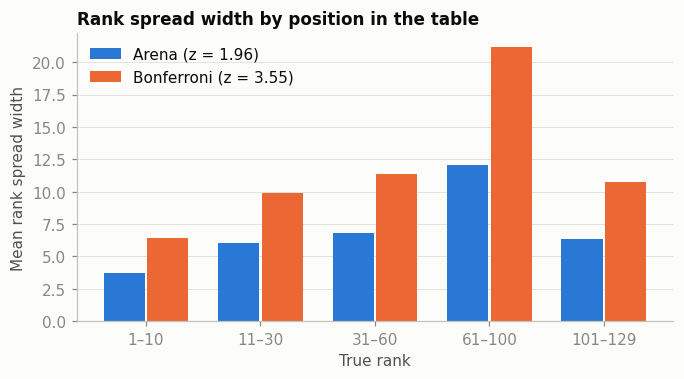

,Arena,Bonferroni,Bonferroni / Arena
True rank,,,
1–10,3.70,6.41,1.73
11–30,6.07,9.88,1.63
31–60,6.79,11.35,1.67
61–100,12.09,21.17,1.75
101–129,6.37,10.74,1.69


In [3]:
tiers = pd.cut(per_model.true_rank, [0, 10, 30, 60, 100, M], labels=["1–10", "11–30", "31–60", "61–100", f"101–{M}"])
width = per_model.groupby(tiers, observed=True)[["arena_mean_width", "bonferroni_mean_width"]].mean()
width.index.name = "True rank"

fig, ax = plt.subplots(figsize=(7, 3.4))
x, bw = np.arange(len(width)), 0.36
for k, (col, color, label) in enumerate([("arena_mean_width", ARENA, "Arena (z = 1.96)"),
                                         ("bonferroni_mean_width", BONF, f"Bonferroni (z = {Z_BONF:.2f})")]):
    ax.bar(x + (k - 0.5) * (bw + 0.02), width[col], width=bw, color=color, label=label, zorder=2)
ax.set_xticks(x, width.index)
ax.set_xlabel("True rank")
ax.set_ylabel("Mean rank spread width")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
ax.set_title("Rank spread width by position in the table")
plt.show()

width.assign(ratio=width.bonferroni_mean_width / width.arena_mean_width).round(2) \
     .rename(columns={"arena_mean_width": "Arena", "bonferroni_mean_width": "Bonferroni", "ratio": "Bonferroni / Arena"})

## 4. Result 3: most of the widening is not needed

To see how much correction the rank spreads actually need, we recomputed them on the same 1,000 datasets with every multiplier $z$ from 1.8 to 4.0. The dots mark Arena ($z = 1.96$), Bonferroni ($z = 3.55$), and the smallest $z$ at which all rank spreads are right 95% of the time.

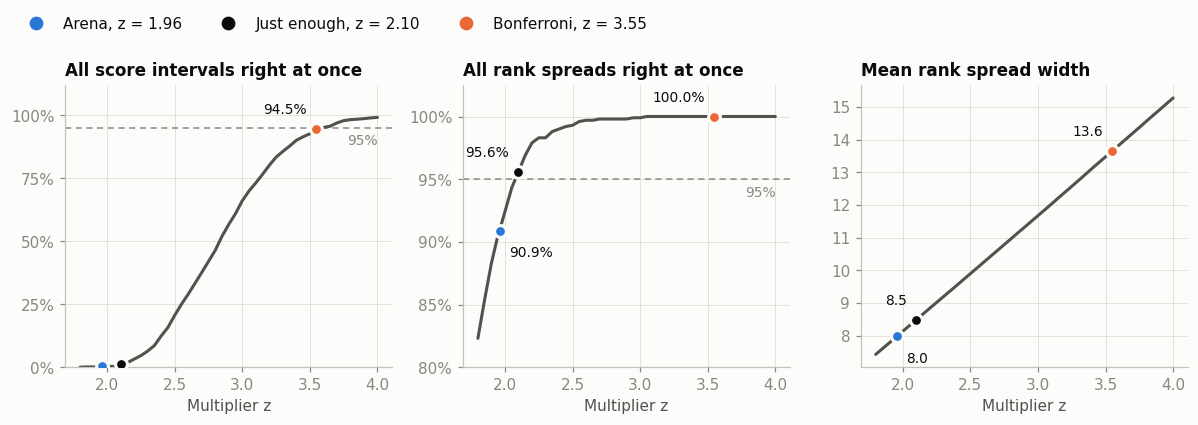

,ci_all_cover,rs_all_cover,rs_all_cover_mc_se,rs_width
z,,,,
1.960,0.003,0.909,0.009,7.990
2.100,0.011,0.956,0.006,8.483
3.548,0.945,1.000,0.000,13.647


In [4]:
marks = [(Z_ARENA, ARENA, f"Arena, z = {Z_ARENA:.2f}"), (Z_ENOUGH, INK, f"Just enough, z = {Z_ENOUGH:.2f}"),
         (Z_BONF, BONF, f"Bonferroni, z = {Z_BONF:.2f}")]
# column, title, label format, labelled points, y-range of a coverage panel (None for width)
panels = [("ci_all_cover", "All score intervals right at once", "{:.1%}", [Z_BONF], (0, 1.12)),
          ("rs_all_cover", "All rank spreads right at once", "{:.1%}", [Z_ARENA, Z_ENOUGH, Z_BONF], (0.8, 1.025)),
          ("rs_width", "Mean rank spread width", "{:.1f}", [Z_ARENA, Z_ENOUGH, Z_BONF], None)]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
for ax, (col, title, fmt, labelled, ylim) in zip(axes, panels):
    ax.plot(sweep.z, sweep[col], color=INK2, lw=2, zorder=2, solid_capstyle="round")
    if ylim:
        ax.axhline(0.95, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
        ax.annotate("95%", (sweep.z.max(), 0.95), xytext=(0, -4), textcoords="offset points",
                    ha="right", va="top", color=MUTED, fontsize=9)
        ax.set_ylim(*ylim)
        ax.set_yticks(np.arange(0, 1.01, 0.25) if ylim[0] == 0 else np.arange(0.8, 1.01, 0.05))
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    for z, color, _ in marks:
        y = np.interp(z, sweep.z, sweep[col])
        ax.scatter([z], [y], s=60, color=color, edgecolors=SURFACE, linewidths=2, zorder=3)
        if z in labelled:   # Arena's label below-right, the others above-left, so no label sits on the curve
            dx, dy, ha, va = (6, -10, "left", "top") if z == Z_ARENA else (-6, 8, "right", "bottom")
            ax.annotate(fmt.format(y), (z, y), xytext=(dx, dy), textcoords="offset points",
                        color=INK, fontsize=9, ha=ha, va=va)
    ax.set_title(title)
    ax.set_xlabel("Multiplier z")
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=c, markersize=8, label=lab) for _, c, lab in marks],
           loc="lower left", bbox_to_anchor=(0.01, 1.0), ncol=3)
fig.tight_layout()
plt.show()

sweep.loc[np.isclose(sweep.z.values[:, None], [Z_ARENA, Z_ENOUGH, Z_BONF]).any(1), ["z", "ci_all_cover", "rs_all_cover", "rs_all_cover_mc_se", "rs_width"]] \
     .round(3).set_index("z")

- **Left:** for all score intervals to be right at once, you really do need $z \approx 3.55$. Bonferroni is exactly the right size for the score intervals.
- **Middle** (the axis starts at 80%): the rank spreads need much less. At $z = 2.10$ all of them are already right 95.6% of the time.
- **Right:** width grows steadily with $z$. Going to $z = 2.10$ costs 6% more width; going to $3.55$ costs 71%.

**Why the gap?** It comes from the overlap rule. Two models are told apart only when their intervals do not overlap at all, which is a stricter standard than testing their difference directly: the gap between them has to be about 1.4 times larger. Because of that built-in buffer, a score interval that misses its true score by a little rarely changes any rank. Bonferroni then adds a second buffer on top of the first.

**Caveat.** $z = 2.10$ was found using the true ranks, which we know only in the simulation. It shows how much correction is needed in this simulated world. It is not a method that can be applied to real data.

## 5. Result 4: the real 2024 leaderboard

The same two procedures applied to the real battles (the fit behind the 2024-08-12 leaderboard). The figure shows the top 20 models by score.

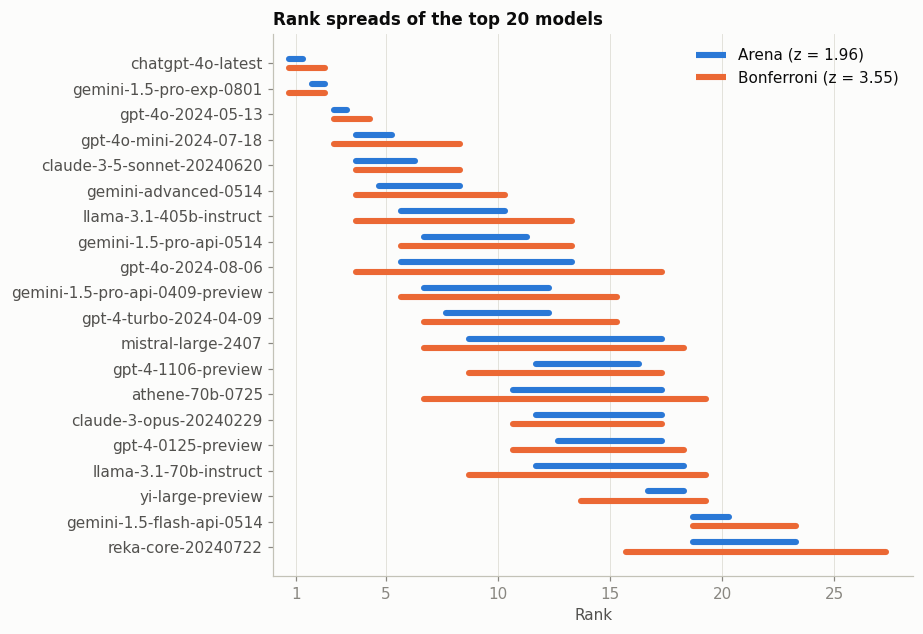

,Arena,Bonferroni
Mean rank spread width,7.9,13.8
Models with a single rank (width 1),4,0
"Model pairs told apart (of 8,256)","7,808","7,430"


In [5]:
top = real.head(20).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(7.5, 6.4))
for off, (p, color, label) in zip([0.18, -0.18], [("arena", ARENA, "Arena (z = 1.96)"),
                                                  ("bonferroni", BONF, f"Bonferroni (z = {Z_BONF:.2f})")]):
    ax.hlines(y + off, top[f"{p}_best"] - 0.3, top[f"{p}_worst"] + 0.3, color=color, lw=4, capstyle="round", label=label)
ax.set_yticks(y, top.model)
ax.tick_params(axis="y", labelcolor=INK2)
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.set_xlim(0, top.bonferroni_worst.max() + 1.5)
ax.set_xlabel("Rank")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right")
ax.set_title("Rank spreads of the top 20 models")
plt.show()

w = {p: real[f"{p}_worst"] - real[f"{p}_best"] + 1 for p in ["arena", "bonferroni"]}
n_pairs = M * (M - 1) // 2
pd.DataFrame({
    "Mean rank spread width": {p: f"{w[p].mean():.1f}" for p in w},
    "Models with a single rank (width 1)": {p: int((w[p] == 1).sum()) for p in w},
    f"Model pairs told apart (of {n_pairs:,})": {p: f"{int(real[f'{p}_orderings'].sum()):,}" for p in w},
}).T.rename(columns={"arena": "Arena", "bonferroni": "Bonferroni"})

- 128 of the 129 rank spreads get wider, by up to 18 ranks.
- No model keeps a single rank. For example, the top two models (chatgpt-4o-latest and gemini-1.5-pro-exp-0801) become tied at ranks 1–2.

## Takeaways

1. **Bonferroni is valid.** With it, all rank spreads were right in every one of the 1,000 simulated datasets, and it never produced a wrong ordering.
2. **Bonferroni is expensive.** Rank spreads become 1.7 times wider, and on the real leaderboard no model keeps a single rank.
3. **Most of that cost is unnecessary.** Arena's overlap rule already supplies most of the protection. In this simulation, raising $z$ from 1.96 to about 2.1 would be enough. A procedure that tests each pair's difference directly gets part of the way: pairwise tests with Holm ([Holm notebook](q2_holm.ipynb)) give rank spreads of 11.3 ranks, against 13.6 for Bonferroni and 8.5 for the z ≈ 2.1 benchmark.

**Limitations.** This is a single simulated world: 129 models with 2024 strengths. Today's Arena has about 400 models, where Bonferroni would need $z = 3.84$. The simulation is idealized in the same ways as Q1 (independent battles, exact Bradley–Terry, fixed strengths).

## Reproduce

```bash
python q2.py --reps 1000 --procedures arena,bonferroni,chi2,chi2_scheffe,pairwise_bonferroni,holm_onesided,holm   # about 4 minutes; writes results/q2_* (always pass all seven: q2.py rewrites these files with only the procedures it is given)
pip install jupyter
jupyter nbconvert --to notebook --execute --inplace notebook/q2_bonferroni.ipynb
```